In [1]:
from pathlib import Path

import torch
import torch.nn.functional as F
from hydra.utils import instantiate

from src.datasets import ShakespeareDataset


In [2]:
checkpoint_path = Path("saved/lrsearch_0.003_xsafalse_s228/model_best.pth")
device = "cpu"

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
config = checkpoint["config"]
model = instantiate(config.model)
model.load_state_dict(checkpoint["state_dict"])
model = model.to(device).eval()


In [3]:
@torch.no_grad()
def get_attention_activations(model, input_ids):
    activations = {}
    handles = []
    training = model.training
    model.eval()

    def capture_qkv(layer_idx, attention):
        def hook(module, inputs, output):
            batch, seq_len, _ = output.shape
            q, k, v = [
                t.reshape(batch, seq_len, attention.num_heads, attention.head_dim)
                .transpose(1, 2)
                for t in output.split(attention.hidden_dim, dim=-1)
            ]
            if attention.rope is not None:
                q, k = attention.rope(q), attention.rope(k)
            scores = (q @ k.transpose(-2, -1)) / attention.head_dim**0.5
            mask = torch.ones(seq_len, seq_len, device=q.device, dtype=torch.bool).tril()
            weights = scores.masked_fill(~mask, float("-inf")).softmax(dim=-1)
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
            activations[layer_idx] = {
                name: tensor.detach().cpu()
                for name, tensor in dict(q=q, k=k, v=v, weights=weights, y=y).items()
            }
        return hook

    def capture_output(layer_idx, attention):
        def hook(module, inputs):
            output = inputs[0]
            batch, seq_len, _ = output.shape
            z = output.reshape(batch, seq_len, attention.num_heads, attention.head_dim)
            activations[layer_idx]["z"] = z.transpose(1, 2).detach().cpu()
        return hook

    for layer_idx, block in enumerate(model.transformer.h):
        attention = block.attn
        handles.append(attention.qkv_proj.register_forward_hook(capture_qkv(layer_idx, attention)))
        handles.append(attention.out_proj.register_forward_pre_hook(capture_output(layer_idx, attention)))

    model(input_ids.to(next(model.parameters()).device))

    for handle in handles:
        handle.remove()
    model.train(training)
    return activations


In [4]:
dataset = ShakespeareDataset(
    data_dir="data/shakespeare",
    split="val",
    block_size=model.block_size,
    tokenizer_name=config.tokenizer_name,
    stride=model.block_size,
)


In [5]:
import matplotlib.pyplot as plt

checkpoint_paths = {
    "SA": Path("saved/lrsearch_0.003_xsafalse_s228/model_best.pth"),
    "XSA": Path("saved/lrsearch_0.003_xsatrue_s228/model_best.pth"),
}
models = {}
for name, path in checkpoint_paths.items():
    saved = torch.load(path, map_location="cpu", weights_only=False)
    models[name] = instantiate(saved["config"].model).to(device).eval()
    models[name].load_state_dict(saved["state_dict"])
    assert models[name].block_size == model.block_size
    assert saved["config"].tokenizer_name == config.tokenizer_name

train_dataset = ShakespeareDataset(
    data_dir="data/shakespeare",
    split="train",
    block_size=model.block_size,
    tokenizer_name=config.tokenizer_name,
)
num_sequences = 1024
batch_size = 8
generator = torch.Generator().manual_seed(1337)
indices = torch.randperm(len(train_dataset), generator=generator)[:num_sequences]
comparison_inputs = torch.stack([train_dataset[i.item()]["input_ids"] for i in indices])


In [6]:
@torch.no_grad()
def similarity_by_layer(model, input_ids, batch_size=8):
    keys = ("value_similarity", "diagonal_attention", "y", "z", "z_norm", "norm_ratio")
    sums = {key: torch.zeros(model.n_layers, dtype=torch.float64) for key in keys}
    counts = {key: torch.zeros(model.n_layers, dtype=torch.float64) for key in keys}
    for batch in input_ids.split(batch_size):
        activations = get_attention_activations(model, batch)
        for layer_idx, values in activations.items():
            y_norm = values["y"].norm(dim=-1)
            z_norm = values["z"].norm(dim=-1)
            sums["z_norm"][layer_idx] += z_norm.double().sum()
            counts["z_norm"][layer_idx] += z_norm.numel()
            valid_y = y_norm > 1e-6
            ratios = z_norm[valid_y] / y_norm[valid_y]
            sums["norm_ratio"][layer_idx] += ratios.double().sum()
            counts["norm_ratio"][layer_idx] += ratios.numel()
            v = values["v"]
            v_norm = v.norm(dim=-1)
            v_unit = F.normalize(v, dim=-1)
            pairwise = v_unit @ v_unit.transpose(-2, -1)
            seq_len = v.shape[-2]
            pairs = ~torch.eye(seq_len, dtype=torch.bool)
            pairs = pairs & (v_norm > 1e-6).unsqueeze(-1) & (v_norm > 1e-6).unsqueeze(-2)
            sums["value_similarity"][layer_idx] += pairwise[pairs].double().sum()
            counts["value_similarity"][layer_idx] += pairs.sum()
            diagonal = values["weights"].diagonal(dim1=-2, dim2=-1)
            sums["diagonal_attention"][layer_idx] += diagonal.double().sum()
            counts["diagonal_attention"][layer_idx] += diagonal.numel()
            for key in ("y", "z"):
                output = values[key]
                valid = (output.norm(dim=-1) > 1e-6) & (v_norm > 1e-6)
                if key == "z" and model.transformer.h[layer_idx].attn.use_xsa:
                    valid[:, :, 0] = False
                similarity = F.cosine_similarity(output, v, dim=-1)
                sums[key][layer_idx] += similarity[valid].double().sum()
                counts[key][layer_idx] += valid.sum()
    return {key: sums[key] / counts[key] for key in keys}

similarities = {
    name: similarity_by_layer(net, comparison_inputs, batch_size)
    for name, net in models.items()
}


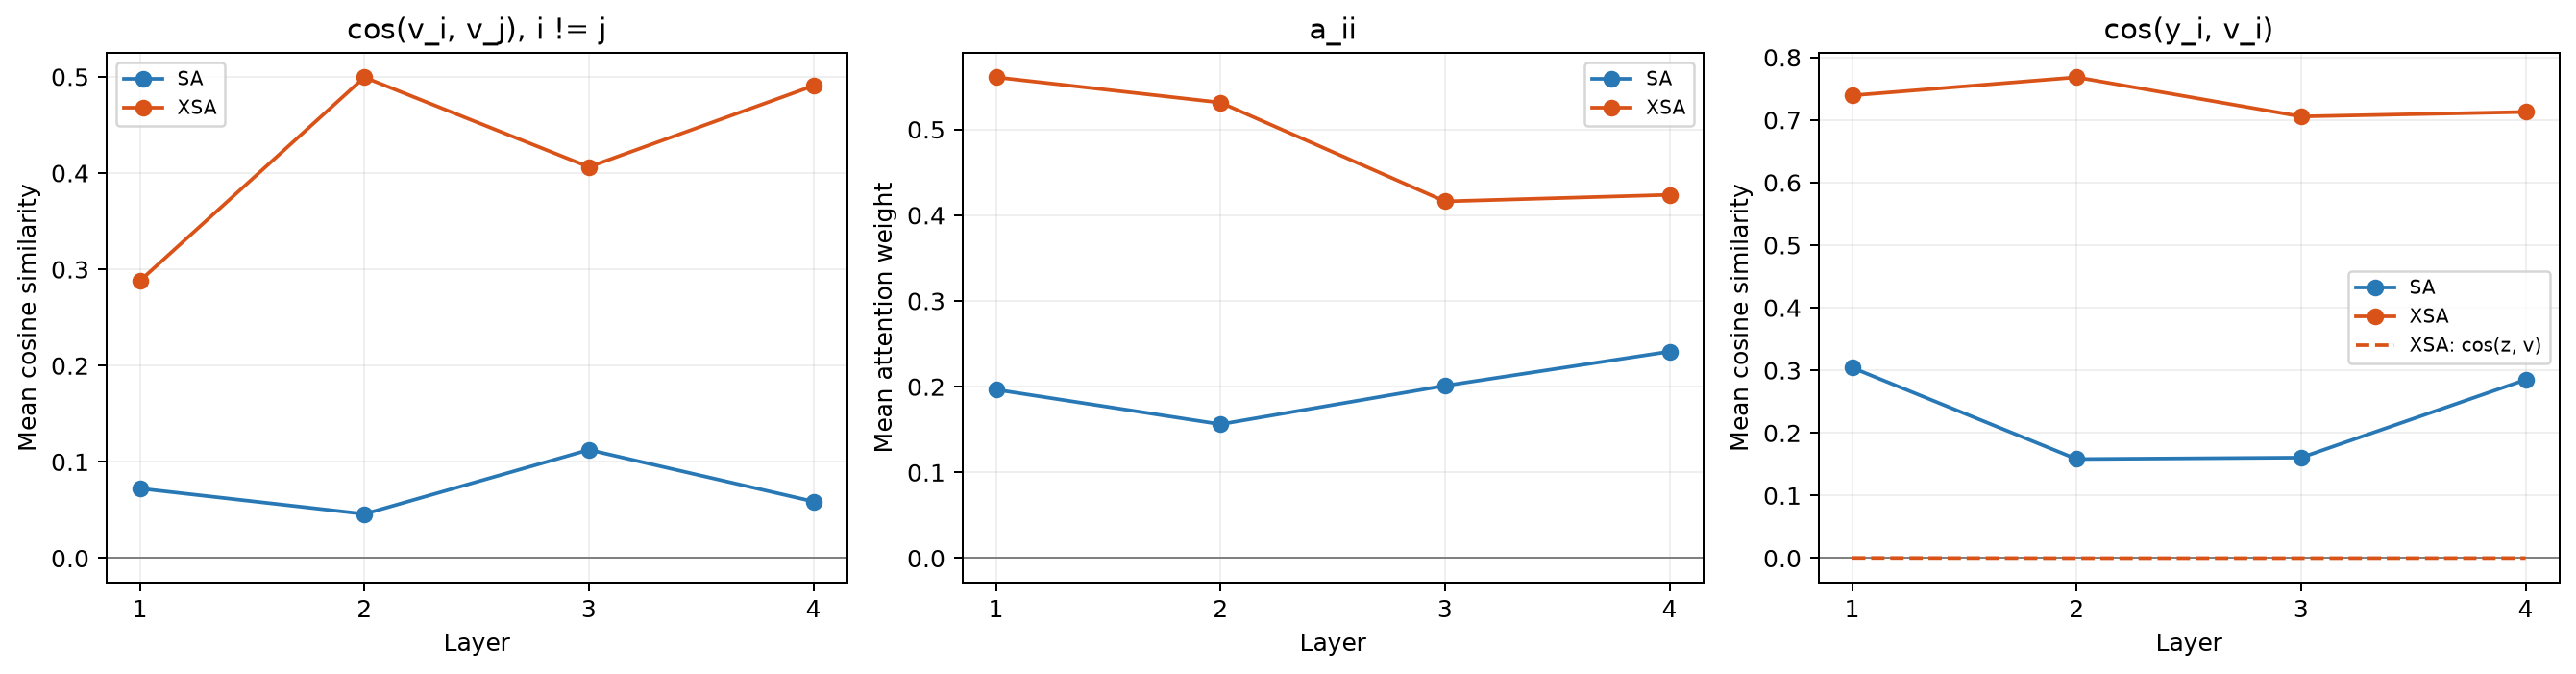

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = {"SA": "#2878B5", "XSA": "#D95319"}
keys = ("value_similarity", "diagonal_attention", "y")
titles = ("cos(v_i, v_j), i != j", "a_ii", "cos(y_i, v_i)")
for ax, key, title in zip(axes, keys, titles):
    for name, values in similarities.items():
        layers = range(1, len(values[key]) + 1)
        ax.plot(layers, values[key].numpy(), marker="o", label=name, color=colors[name])
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set(title=title, xlabel="Layer", xticks=list(layers))
    ax.grid(alpha=0.2)
axes[2].plot(layers, similarities["XSA"]["z"].numpy(), "--", color=colors["XSA"], label="XSA: cos(z, v)")
for ax in axes:
    ax.legend(fontsize=8)
axes[0].set_ylabel("Mean cosine similarity")
axes[1].set_ylabel("Mean attention weight")
axes[2].set_ylabel("Mean cosine similarity")
fig.tight_layout()
plt.show()


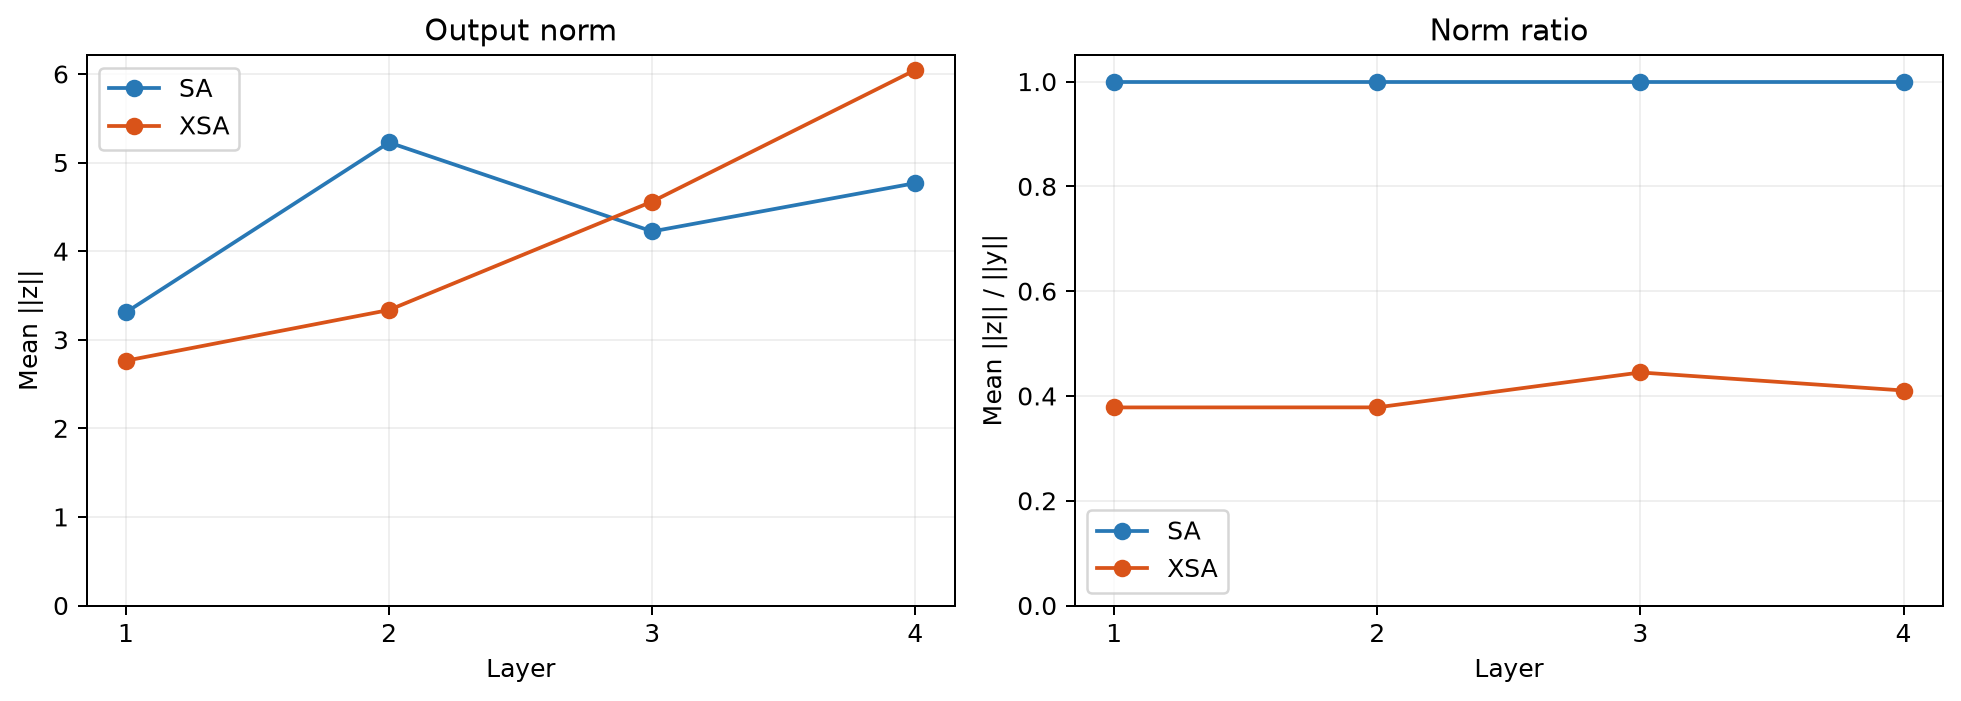

In [8]:
norm_fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, key, title, ylabel in zip(
    axes,
    ("z_norm", "norm_ratio"),
    ("Output norm", "Norm ratio"),
    ("Mean ||z||", "Mean ||z|| / ||y||"),
):
    for name, values in similarities.items():
        layers = range(1, len(values[key]) + 1)
        ax.plot(layers, values[key].numpy(), marker="o", label=name, color=colors[name])
    ax.set(title=title, xlabel="Layer", ylabel=ylabel, xticks=list(layers))
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend()
axes[1].set_ylim(0, 1.05)
norm_fig.tight_layout()
plt.show()
